In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns

In [65]:
def build_hierarchy(hierarchy_file):
    h_graph = nx.DiGraph()
    with open(hierarchy_file, "r") as f:
        for line in f:
            if not line.startswith("R-HSA"):
                continue  # don't care about other species
            split = line.strip().split("\t")
            src, dest = split[0], split[1]
            h_graph.add_edge(src, dest)

    return h_graph


hierarchy = build_hierarchy("../data/ReactomePathwaysRelation.txt")
print(hierarchy)

DiGraph with 2883 nodes and 2899 edges


In [66]:
pathways = pd.read_csv("../data/reactome_pathways_filtered.csv")
pathway_names = pathways.groupby("1")["3"].first().to_dict()

In [67]:
found_pathways = pd.read_csv("../data/pathways_all", sep="\t")
found_pathways

,pathway_id,real_pct,random_pct,name
0,R-HSA-9764790,1.0,1.000000,Positive Regulation of CDH1 Gene Transcription
1,R-HSA-164940,1.0,0.750000,Nef mediated downregulation of MHC class I com...
2,R-HSA-198323,1.0,1.000000,AKT phosphorylates targets in the cytosol
3,R-HSA-162658,1.0,0.750000,Golgi Cisternae Pericentriolar Stack Reorganiz...
4,R-HSA-2470946,1.0,0.444444,Cohesin Loading onto Chromatin
...,...,...,...,...
1410,R-HSA-1430728,1.0,0.695407,Metabolism
1411,R-HSA-168256,1.0,0.760959,Immune System
1412,R-HSA-1643685,1.0,0.786607,Disease
1413,R-HSA-392499,1.0,0.731771,Metabolism of proteins


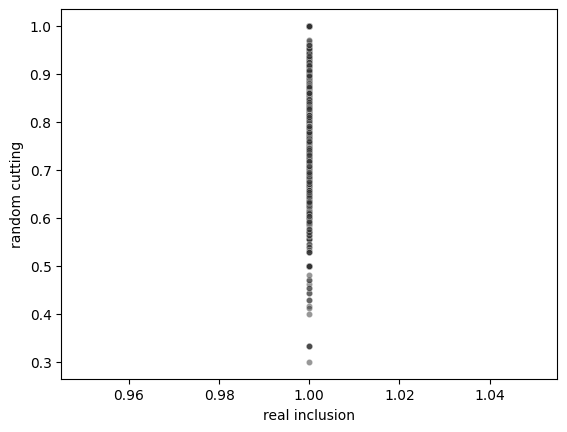

In [68]:
sns.scatterplot(x=found_pathways["real_pct"], y=found_pathways["random_pct"], s=20, alpha=0.5, color=".2")
plt.xlabel("real inclusion")
plt.ylabel("random cutting")
plt.show()

In [69]:
def top_level_pathway(pathway: str, hierarchy: nx.DiGraph):
    if len(list(hierarchy.predecessors(pathway))) == 0:
        return pathway_names.get(pathway, pathway)
    return top_level_pathway(next(iter(hierarchy.predecessors(pathway))), hierarchy)

In [70]:
found_pathways["top_level"] = found_pathways["pathway_id"].apply(lambda x: top_level_pathway(x, hierarchy))
found_pathways

,pathway_id,real_pct,random_pct,name,top_level
0,R-HSA-9764790,1.0,1.000000,Positive Regulation of CDH1 Gene Transcription,Cell-Cell communication
1,R-HSA-164940,1.0,0.750000,Nef mediated downregulation of MHC class I com...,Disease
2,R-HSA-198323,1.0,1.000000,AKT phosphorylates targets in the cytosol,Signal Transduction
3,R-HSA-162658,1.0,0.750000,Golgi Cisternae Pericentriolar Stack Reorganiz...,Cell Cycle
4,R-HSA-2470946,1.0,0.444444,Cohesin Loading onto Chromatin,Cell Cycle
...,...,...,...,...,...
1410,R-HSA-1430728,1.0,0.695407,Metabolism,Metabolism
1411,R-HSA-168256,1.0,0.760959,Immune System,Immune System
1412,R-HSA-1643685,1.0,0.786607,Disease,Disease
1413,R-HSA-392499,1.0,0.731771,Metabolism of proteins,Metabolism of proteins


In [71]:
found_pathways[found_pathways["real_pct"] > 0.8]["top_level"].value_counts()

top_level
Signal Transduction                     228
Disease                                 207
Immune System                           160
Metabolism                              138
Cell Cycle                              104
Gene expression (Transcription)          82
Metabolism of proteins                   82
Developmental Biology                    49
DNA Repair                               47
Metabolism of RNA                        43
Cellular responses to stimuli            39
Vesicle-mediated transport               29
Transport of small molecules             28
Hemostasis                               23
Programmed Cell Death                    23
Neuronal System                          22
Cell-Cell communication                  21
Chromatin organization                   20
Extracellular matrix organization        19
Organelle biogenesis and maintenance     13
Autophagy                                 8
Muscle contraction                        6
DNA Replication       

In [72]:
found_pathways[found_pathways["random_pct"] > 0.8]["top_level"].value_counts()

top_level
Signal Transduction                     135
Disease                                  92
Immune System                            87
Gene expression (Transcription)          56
Developmental Biology                    29
DNA Repair                               26
Cell Cycle                               24
Metabolism                               22
Programmed Cell Death                    21
Metabolism of proteins                   19
Cell-Cell communication                  18
Extracellular matrix organization        15
Cellular responses to stimuli            15
Chromatin organization                   11
Hemostasis                               10
Vesicle-mediated transport                8
Neuronal System                           8
Transport of small molecules              8
Metabolism of RNA                         6
Organelle biogenesis and maintenance      4
Sensory Perception                        2
Autophagy                                 2
Drug ADME             

In [73]:
found_pathways[(found_pathways["real_pct"] > 0.8) & (found_pathways["random_pct"] > 0.8)]

,pathway_id,real_pct,random_pct,name,top_level
0,R-HSA-9764790,1.0,1.000000,Positive Regulation of CDH1 Gene Transcription,Cell-Cell communication
2,R-HSA-198323,1.0,1.000000,AKT phosphorylates targets in the cytosol,Signal Transduction
6,R-HSA-418885,1.0,0.888889,DCC mediated attractive signaling,Developmental Biology
7,R-HSA-5358606,1.0,0.833333,Mismatch repair (MMR) directed by MSH2:MSH3 (M...,DNA Repair
8,R-HSA-877312,1.0,1.000000,Regulation of IFNG signaling,Immune System
...,...,...,...,...,...
1380,R-HSA-449147,1.0,0.832031,Signaling by Interleukins,Immune System
1384,R-HSA-5663202,1.0,0.860558,Diseases of signal transduction by growth fact...,Disease
1388,R-HSA-9006934,1.0,0.828383,Signaling by Receptor Tyrosine Kinases,Signal Transduction
1393,R-HSA-1266738,1.0,0.825986,Developmental Biology,Developmental Biology
